# Module 4 – Part A: CNN Image Classification on Mini-ImageNet

**Goal:** train a convolutional neural network to classify the mini-ImageNet subset (33 classes, 84×84 RGB images) and study how these network parameters affect classification performance:

1. number of convolutional (conv) layers
2. number of fully connected (fc) layers
3. number of filters in different layers
4. max pooling
5. training time (number of epochs)
6. stride

**Approach**

* One configurable CNN class is used for every experiment, so each run differs from the **baseline** in exactly one parameter.
* Every model is trained with the same optimizer, learning rate, batch size, augmentation and seed, so differences in accuracy come from the parameter being studied.
* The **validation** set is used to choose the best model; the **test** set is used to report performance.
* The best configuration is then trained for longer to get the final model, and its misclassified test images are analysed.

**Notebook outline**

1. Setup & configuration
2. Load the dataset
3. Preprocessing & augmentation
4. Configurable CNN
5. Training & evaluation functions
6. Experiments (parameter study)
7. Results table
8. Effect of training time (epochs)
9. Final model


In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models # add models to the list
from torchvision.utils import make_grid
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

# ignore harmless warnings
import warnings
warnings.filterwarnings("ignore")

torch.manual_seed(42)

### 1. Create a list of image filenames & read some basic stats of Train Images

In [2]:
# Do some basic checks on the dataset to see basic statistics of the images like mean width ,
#  height
from PIL import Image
from IPython.display import display

path = 'AI_ML_Assignment_4_Dataset\\train'
img_names = []

# Create a list of all the filenames in the training dataset
for folder, subfolders, filenames in os.walk(path):
    for img in filenames:
        img_names.append(folder+'\\'+img)
        
print('Total Images In Training: ',len(img_names))

# Assess basic statistics of the images in the training dataset
img_sizes = []
rejected = []

for item in img_names:
    try:
        with Image.open(item) as img:
            img_sizes.append(img.size)
    except:
        rejected.append(item)
        
print(f'Images read:  {len(img_sizes)}')
print(f'Rejects Images: {len(rejected)}')

Total Images In Training:  13200
Images read:  13200
Rejects Images: 0


In [3]:
# Convert the list to a DataFrame
df = pd.DataFrame(img_sizes)

# Run summary statistics on image widths
df[0].describe()

count    13200.0
mean        84.0
std          0.0
min         84.0
25%         84.0
50%         84.0
75%         84.0
max         84.0
Name: 0, dtype: float64

In [4]:
# Run summary statistics on image heights
df[1].describe()

count    13200.0
mean        84.0
std          0.0
min         84.0
25%         84.0
50%         84.0
75%         84.0
max         84.0
Name: 1, dtype: float64

#### This tells us that the images in training are all with width 84 & height 84

### 2. Define transformations
Define basic transformation to be carried out on the images for data augmentation convert to Tensor and normalization.

In [2]:
train_transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406],
                             [0.229, 0.224, 0.225])
    ])

test_transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406],
                             [0.229, 0.224, 0.225])
    ])

### 3. Prepare train and test sets, loaders

In [6]:
# Load Training Data
root = 'AI_ML_Assignment_4_Dataset'

train_data = datasets.ImageFolder(os.path.join(root, 'train'), transform=train_transform)
train_loader = DataLoader(train_data, batch_size=10, shuffle=True)

test_data = datasets.ImageFolder(os.path.join(root, 'test'), transform=test_transform)
test_loader = DataLoader(test_data, batch_size=10, shuffle=True)

# List out class names in Training Data
class_names = train_data.classes
print(f'Class Names in Training Data: {class_names}')
print(f'Number of Classes: {len(class_names)}')
print(f'Training images available: {len(train_data)}')
print(f'Test images available: {len(test_data)}')

Class Names in Training Data: ['african_hunting_dog', 'ant', 'ashcan', 'black_footed_ferret', 'bookshop', 'carousel', 'catamaran', 'cocktail_shaker', 'combination_lock', 'consomme', 'coral_reef', 'dalmatian', 'dishrag', 'fire_screen', 'goose', 'green_mamba', 'king_crab', 'ladybug', 'lion', 'lipstick', 'miniature_poodle', 'orange', 'organ', 'parallel_bars', 'photocopier', 'rhinoceros_beetle', 'slot', 'snorkel', 'spider_web', 'toucan', 'triceratops', 'unicycle', 'vase']
Number of Classes: 33
Training images available: 13200
Test images available: 3300


Label: [31 12 27  9  0 17 11  5  8 18]
Class: unicycle dishrag snorkel consomme african_hunting_dog ladybug dalmatian carousel combination_lock lion


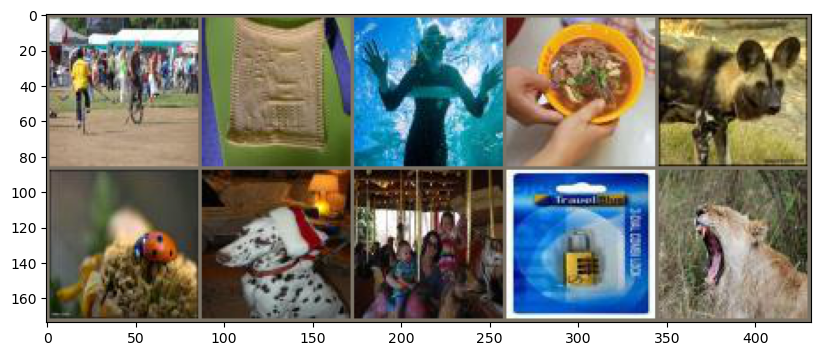

In [7]:
# Grab the first batch of 10 images
for images,labels in train_loader: 
    break

# Print the labels
print('Label:', labels.numpy())
print('Class:', *np.array([class_names[i] for i in labels]))

im = make_grid(images, nrow=5)  # the default nrow is 8

# Inverse normalize the images
inv_normalize = transforms.Normalize(
    mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
    std=[1/0.229, 1/0.224, 1/0.225]
)
im_inv = inv_normalize(im)

# Print the images
plt.figure(figsize=(12,4))
plt.imshow(np.transpose(im_inv.numpy(), (1, 2, 0)));

### 4. Configurable CNN

A single model class covers all the experiments. Its parameters are:

| Parameter | Meaning |
|---|---|
| `n_conv` | number of conv blocks (Conv 3×3 → BatchNorm → ReLU → [MaxPool 2×2]) |
| `base_filters` | filters in the first conv layer; each following layer doubles it (e.g. 32 → 64 → 128) |
| `fc` | list of hidden fully connected layer sizes (an output layer with 33 units is always added) |
| `pool` | whether a 2×2 max pooling layer follows each conv layer |
| `stride` | stride of every conv layer |

After the last conv block, an **adaptive average pool** reduces the feature maps to a fixed 4×4 grid. This keeps the input size of the first fc layer the same (`filters × 4 × 4`) across experiments. Without it, removing max pooling would make the fc layer enormous (e.g. 128 × 84 × 84 ≈ 900k inputs), and the comparison would really be about fc size rather than pooling.

Batch normalisation and dropout (0.5 in the hidden fc layers) are kept constant in all experiments.

In [3]:
class ConvolutionalNeuralNetwork(nn.Module):
    def __init__(self, conv_channels=[6, 16], fc_units=[120, 84], num_classes=33,
                 kernel_size=3, stride=1, pool=True, img_size=84,
                 dropout=0.0, conv_dropout=0.0):
        super().__init__()
        self.pool = pool
        n_conv = len(conv_channels)

        # kernel_size / stride: a single int (same for all conv layers) or a list (one per conv layer)
        kernel_sizes = kernel_size if isinstance(kernel_size, (list, tuple)) else [kernel_size] * n_conv
        strides      = stride      if isinstance(stride, (list, tuple))      else [stride] * n_conv
        assert len(kernel_sizes) == n_conv, 'kernel_size list must have one entry per conv layer'
        assert len(strides) == n_conv,      'stride list must have one entry per conv layer'

        # One Conv2d per entry in conv_channels
        self.convs = nn.ModuleList()
        in_ch = 3   # input image has 3 channels (RGB)
        for out_ch, k, s in zip(conv_channels, kernel_sizes, strides):
            self.convs.append(nn.Conv2d(in_ch, out_ch, k, s))
            in_ch = out_ch

        # Dropout2d zeroes whole feature maps (channels) in the conv layers
        self.conv_drop = nn.Dropout2d(conv_dropout)
        # Dropout zeroes individual units in the fc layers
        self.fc_drop = nn.Dropout(dropout)

        # Work out the flattened size with a dummy image (also checks the image isn't shrunk to nothing)
        with torch.no_grad():
            out = self._conv_forward(torch.zeros(1, 3, img_size, img_size))
        self.feature_map_size = tuple(out.shape[2:])
        self.flat_size = out.numel()

        # One Linear per entry in fc_units, plus the output layer
        self.fcs = nn.ModuleList()
        in_f = self.flat_size
        for units in fc_units:
            self.fcs.append(nn.Linear(in_f, units))
            in_f = units
        self.out = nn.Linear(in_f, num_classes)

    def _conv_forward(self, X):
        for conv in self.convs:
            X = conv(X)                       # (size - kernel)/stride + 1
            if self.pool:
                X = F.max_pool2d(X, 2, 2)     # size / 2 (rounded down)
            X = F.relu(X)
            X = self.conv_drop(X)             # does nothing if conv_dropout=0
        return X

    def forward(self, X):
        X = self._conv_forward(X)
        X = X.view(-1, self.flat_size)
        for fc in self.fcs:
            X = F.relu(fc(X))
            X = self.fc_drop(X)               # does nothing if dropout=0
        X = self.out(X)
        return F.log_softmax(X, dim=1)


Including the bias terms for each layer, the total number of parameters being trained is:<br>

$$
\begin{aligned}
&(3\times6\times3\times3)+6+(6\times16\times3\times3)+16+(5776\times120)+120+(120\times84)+84+(84\times33)+33\\
&= 162+6+864+16+693120+120+10080+84+2772+33 \\
&= 7{,}07{,}257
\end{aligned}
$$ 

### 5. Training & evaluation functions

In [9]:
import time

def train_network(model, train_loader, test_loader, epochs=10, lr=0.001, print_every=200):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    

    history = {'train_loss': [], 'test_loss': [], 'train_acc': [], 'test_acc': []}
    n_train = len(train_loader.dataset)
    start = time.time()

    for epoch in range(epochs):
        # ---- training ----
        model.train()
        trn_corr, trn_loss, trn_total = 0, 0.0, 0
        for b, (X_train, y_train) in enumerate(train_loader, start=1):
            X_train, y_train = X_train.to(device), y_train.to(device)
            y_pred = model(X_train)
            loss = criterion(y_pred, y_train)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            trn_loss += loss.item() * len(y_train)
            trn_corr += (y_pred.argmax(1) == y_train).sum().item()
            trn_total += len(y_train)

            # interim results
            if b % print_every == 0:
                print(f'epoch: {epoch+1:2}  batch: {b:4} [{trn_total:6}/{n_train}]  '
                      f'loss: {loss.item():10.8f}  accuracy: {100 * trn_corr / trn_total:7.3f}%')

        # ---- testing ----
        model.eval()
        tst_corr, tst_loss, tst_total = 0, 0.0, 0
        with torch.no_grad():
            for X_test, y_test in test_loader:
                X_test, y_test = X_test.to(device), y_test.to(device)
                y_val = model(X_test)
                tst_loss += criterion(y_val, y_test).item() * len(y_test)
                tst_corr += (y_val.argmax(1) == y_test).sum().item()
                tst_total += len(y_test)

        history['train_loss'].append(trn_loss / trn_total)
        history['test_loss'].append(tst_loss / tst_total)
        history['train_acc'].append(100 * trn_corr / trn_total)
        history['test_acc'].append(100 * tst_corr / tst_total)

        # end-of-epoch summary
        print(f'>> epoch {epoch+1:2}/{epochs} done  '
              f'train loss {history["train_loss"][-1]:.4f}  train acc {history["train_acc"][-1]:6.2f}%  '
              f'test loss {history["test_loss"][-1]:.4f}  test acc {history["test_acc"][-1]:6.2f}%  '
              f'[{(time.time() - start) / 60:.1f} min]\n')

    history['time_min'] = (time.time() - start) / 60
    print(f'Duration: {history["time_min"]:.1f} min\n')
    return model, history


### 6. Experiments (parameter study)

In [123]:
configs = {
    '2 conv, 3 fc':dict(conv_channels=[6, 16],fc_units=[120, 84]),
    '3 conv (32-64-128), 2 fc, kernel 3': dict(conv_channels=[32, 64, 128], fc_units=[256], kernel_size=3),
    '4 conv, 1 fc, stride 2, no pool': dict(conv_channels=[16, 32, 64, 128], fc_units=[],
                                             stride=2, pool=False),
    '4 conv (64-192-384-256), 3 fc, kernel 5-3-3-3, dropout': dict(conv_channels=[64, 192, 384, 256], fc_units=[1024, 512],
                                                                    kernel_size=[5, 3, 3, 3],dropout=0.5
                                                      )
}

EPOCHS = 10
results = {}          # name -> history dict (per-epoch losses/accuracies)
trained_models = {}   # name -> trained model

for name, cfg in configs.items():
    print(f'===== {name} =====')
    torch.manual_seed(42)   # same starting point for a fair comparison
    model = ConvolutionalNeuralNetwork(**cfg)
    print(f'Parameters: {sum(p.numel() for p in model.parameters()):,}')
    trained_models[name], results[name] = train_network(model, train_loader, test_loader, epochs=EPOCHS)

===== 2 conv, 3 fc =====
Parameters: 707,257
epoch:  1  batch:  200 [  2000/13200]  loss: 3.38114619  accuracy:   7.500%
epoch:  1  batch:  400 [  4000/13200]  loss: 2.79609084  accuracy:  10.450%
epoch:  1  batch:  600 [  6000/13200]  loss: 2.43293142  accuracy:  12.700%
epoch:  1  batch:  800 [  8000/13200]  loss: 3.16033554  accuracy:  14.075%
epoch:  1  batch: 1000 [ 10000/13200]  loss: 2.50010586  accuracy:  15.630%
epoch:  1  batch: 1200 [ 12000/13200]  loss: 2.87171745  accuracy:  16.600%
>> epoch  1/10 done  train loss 2.9644  train acc  17.14%  test loss 2.8033  test acc  21.94%  [0.6 min]

epoch:  2  batch:  200 [  2000/13200]  loss: 3.08901954  accuracy:  26.650%
epoch:  2  batch:  400 [  4000/13200]  loss: 2.64314723  accuracy:  28.150%
epoch:  2  batch:  600 [  6000/13200]  loss: 2.64023972  accuracy:  28.383%
epoch:  2  batch:  800 [  8000/13200]  loss: 2.09872580  accuracy:  29.450%
epoch:  2  batch: 1000 [ 10000/13200]  loss: 2.19437265  accuracy:  29.890%
epoch:  2  ba

### 7. Download a pretrained model - AlexNet
Torchvision has a number of proven models available through <a href='https://pytorch.org/docs/stable/torchvision/models.html#classification'><tt><strong>torchvision.models</strong></tt></a>:
<ul>
<li><a href="https://arxiv.org/abs/1404.5997">AlexNet</a></li>
<li><a href="https://arxiv.org/abs/1409.1556">VGG</a></li>
<li><a href="https://arxiv.org/abs/1512.03385">ResNet</a></li>
<li><a href="https://arxiv.org/abs/1602.07360">SqueezeNet</a></li>
<li><a href="https://arxiv.org/abs/1608.06993">DenseNet</a></li>
<li><a href="https://arxiv.org/abs/1512.00567">Inception</a></li>
<li><a href="https://arxiv.org/abs/1409.4842">GoogLeNet</a></li>
<li><a href="https://arxiv.org/abs/1807.11164">ShuffleNet</a></li>
<li><a href="https://arxiv.org/abs/1801.04381">MobileNet</a></li>
<li><a href="https://arxiv.org/abs/1611.05431">ResNeXt</a></li>
</ul>
These have all been trained on the <a href='http://www.image-net.org/'>ImageNet</a> database of images. Our only task is to reduce the output of the fully connected layers from (typically) 1000 categories to just 33.

To access the models, you can construct a model with random weights by calling its constructor:<br>
<pre>resnet18 = models.resnet18()</pre>

In [125]:
AlexNetmodel = models.alexnet(pretrained=True)

#### Modify the classifier
Next we need to modify the fully connected layers to produce a binary output. The section is labeled "classifier" in the AlexNet model.<br>
Note that when we assign new layers, their parameters default to <tt>.requires_grad=True</tt>.

In [126]:
# 1. Freeze all pretrained weights
for param in AlexNetmodel.parameters():
    param.requires_grad = False

# 2. Keep the pretrained fc layers; replace only the last one (4096 -> 1000 becomes 4096 -> 33)
torch.manual_seed(42)
AlexNetmodel.classifier[6] = nn.Sequential(
    nn.Linear(4096, 33),
    nn.LogSoftmax(dim=1)
)
print('Trainable parameters:', sum(p.numel() for p in AlexNetmodel.parameters() if p.requires_grad))

Trainable parameters: 135201


In [127]:
AlexNetmodel

AlexNet(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 192, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (avgpool): AdaptiveAvgPool2d(output_size=(6, 6))
  (classifier): Sequential(
    (0): Dropout(p=0.5, inplace=False)
    (1): Linear(in_features=9216, out_features=4096, bias=True)
 

In [128]:
# Transforms -  Resize to 224 and normalise with the ImageNet mean and std, because the pretrained weights expect inputs normalised that way:
train_transform = transforms.Compose([
    transforms.Resize(224),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

test_transform = transforms.Compose([
    transforms.Resize(224),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

train_data = datasets.ImageFolder(os.path.join(root, 'train'), transform=train_transform)
test_data  = datasets.ImageFolder(os.path.join(root, 'test'),  transform=test_transform)

train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
test_loader  = DataLoader(test_data,  batch_size=32, shuffle=False)

torch.manual_seed(42)
AlexNetmodel, alexnet_history = train_network(AlexNetmodel, train_loader, test_loader,
                                              epochs=5, print_every=100)
results['AlexNet (pretrained)'] = alexnet_history


epoch:  1  batch:  100 [  3200/13200]  loss: 0.62967682  accuracy:  62.906%
epoch:  1  batch:  200 [  6400/13200]  loss: 0.70398927  accuracy:  68.672%
epoch:  1  batch:  300 [  9600/13200]  loss: 1.41071880  accuracy:  70.240%
epoch:  1  batch:  400 [ 12800/13200]  loss: 0.30076599  accuracy:  71.648%
>> epoch  1/5 done  train loss 1.0040  train acc  71.77%  test loss 0.8573  test acc  75.09%  [3.1 min]

epoch:  2  batch:  100 [  3200/13200]  loss: 0.43317997  accuracy:  85.156%
epoch:  2  batch:  200 [  6400/13200]  loss: 0.63928896  accuracy:  84.125%
epoch:  2  batch:  300 [  9600/13200]  loss: 0.82197481  accuracy:  83.438%
epoch:  2  batch:  400 [ 12800/13200]  loss: 0.46295452  accuracy:  82.844%
>> epoch  2/5 done  train loss 0.5760  train acc  82.77%  test loss 0.7590  test acc  78.52%  [6.2 min]

epoch:  3  batch:  100 [  3200/13200]  loss: 0.35345179  accuracy:  86.312%
epoch:  3  batch:  200 [  6400/13200]  loss: 0.43536150  accuracy:  86.609%
epoch:  3  batch:  300 [  9600

### Observations: parameter study and best model

All CNNs were trained from scratch with the same setup: Adam (lr = 0.001), 10 epochs, seed 42, 84×84 inputs, and no padding. Each conv block is **Conv2d → MaxPool 2×2 → ReLU** (except Model 3, which has no pooling).

#### Model definitions

| Model | Conv layers (filters) | Kernel sizes | Stride | Max pooling | FC layers (units) | Dropout | Parameters |
|---|---|---|---|---|---|---|---|
| 1 | 2 (6 → 16) | 3, 3 | 1 | Yes | 3 (120 → 84 → 33) | – | 707,257 |
| **2** | **3 (32 → 64 → 128)** | **3, 3, 3** | **1** | **Yes** | **2 (256 → 33)** | **–** | **2,199,137** |
| 3 | 4 (16 → 32 → 64 → 128) | 3, 3, 3, 3 | 2 | No | 1 (33) | – | 165,057 |
| 4 | 4 (64 → 192 → 384 → 256), AlexNet-style | 5, 3, 3, 3 | 1 | Yes | 3 (1024 → 512 → 33) | 0.5 | 4,566,625 |
| AlexNet *(pretrained, reference only)* | 5 (frozen) | 11, 5, 3, 3, 3 | 4, 1, 1, 1, 1 | Yes | 3 (frozen 4096 → 4096, trained 33) | 0.5 | 135,201 trainable |

#### Results

| Model | Final train acc (%) | Final test acc (%) | Best test acc (%) | Time (min) |
|---|---|---|---|---|
| 1. 2 conv, 3 fc | 90.64 | 28.58 | 33.27 | 6.58 |
| **2. 3 conv (32-64-128), 2 fc, kernel 3** ✅ | **92.93** | **35.45** | **40.55** | **12.77** |
| 3. 4 conv, 1 fc, stride 2, no pool | 85.08 | 34.76 | 38.33 | 6.66 |
| 4. 4 conv (64-192-384-256), 3 fc, kernel 5-3-3-3, dropout 0.5 | 31.05 | 28.55 | 29.18 | 37.87 |
| AlexNet (pretrained) *(reference, 5 epochs)* | 89.91 | 78.09 | 78.79 | 14.51 |

#### Best model: Model 2 – 3 conv layers (32 → 64 → 128), 3×3 kernels, max pooling, 2 fc layers (256 → 33)

Model 2 achieves the **highest test accuracy of our trained CNNs: 40.55%**, at epoch 4. It is selected as our best model and is used for Part B. The pretrained AlexNet is included **only as a reference point**. It was pretrained on ImageNet, of which mini-ImageNet is a subset, so it is not a like-for-like comparison and is not used as our model.

#### Observations

* **More conv layers and filters → better features (Models 1 vs 2).** Model 2 (3 conv layers, 32 → 64 → 128 filters) beats Model 1 (2 conv layers, 6 → 16 filters) by **+7.3 points** (40.55% vs 33.27%). With only 6 and 16 filters, Model 1 cannot learn enough distinct patterns to separate 33 classes.
* **Stride instead of pooling is an efficient alternative (Model 3).** Model 3 uses stride-2 convolutions instead of max pooling, and a single fc layer. It reaches **38.33%**, only 2.2 points below Model 2, with **13× fewer parameters** (165k vs 2.2M) and **half the training time** (6.66 vs 12.77 min).
* **FC layers hold most of the parameters but add little.** In Model 2, the first fc layer (8,192 → 256) holds ~2.1M of its 2.2M parameters. Model 3, with only the output fc layer, performs almost as well. Extra fc capacity mainly helps the network memorise the training set.
* **A bigger AlexNet-style model underfits (Model 4).** Despite having the most parameters (4.6M) and the widest conv layers, Model 4 reaches only **29.18%**, with training accuracy of just **31.05%** after 10 epochs. It is **underfitting**: 50% dropout and wide layers, without batch normalisation, make a deep network trained from scratch learn very slowly. Its train–test gap is tiny (~2.5 points), which shows that dropout prevents overfitting very effectively. But 10 epochs isn't enough for it to learn. It is also by far the slowest model (37.87 min, ~3.8 min/epoch).
* **Training time (epochs): Models 1–3 overfit after a few epochs.** Training accuracy reaches 85–93%, but final test accuracy is 3–5 points below each model's best. Model 2 peaks at **epoch 4** (40.55%) and ends at 35.45% after 10 epochs, while its test loss more than doubles. Training longer without regularisation makes these models worse. Early stopping at the best epoch is the right choice.
* **Overfitting vs. underfitting.** Models 1–3 have train–test gaps of **50–62 points** (e.g. Model 2: 92.93% vs 35.45%), a clear sign of overfitting on 400 images per class. Model 4 shows the opposite problem. The best results lie between the two: enough capacity to learn, with some regularisation to generalise.
* **Pretrained features dominate.** AlexNet with frozen ImageNet features reaches **78.79%**, about 2× our best model, in only 5 epochs. With limited data, learning good features from scratch is the main limitation of our models.

#### Possible improvements to the best model
* **Early stopping:** keep Model 2's weights from epoch 4 (its best epoch) instead of epoch 10.
* **Moderate dropout** (e.g. 0.3) on Model 2's fc layer to reduce its overfitting. 0.5 was too strong for Model 4.
* **Batch normalisation** after each conv layer, so deeper models like Model 4 train faster.
* **Data augmentation** (random flips and crops) to make better use of the 400 images per class.


,Final train acc (%),Final test acc (%),Best test acc (%),Time (min)
"2 conv, 3 fc",90.64,28.58,33.27,6.58
"3 conv (32-64-128), 2 fc, kernel 3",92.93,35.45,40.55,12.77
"4 conv, 1 fc, stride 2, no pool",85.08,34.76,38.33,6.66
"4 conv (64-192-384-256), 3 fc, kernel 5-3-3-3, dropout",31.05,28.55,29.18,37.87
AlexNet (pretrained),89.91,78.09,78.79,14.51


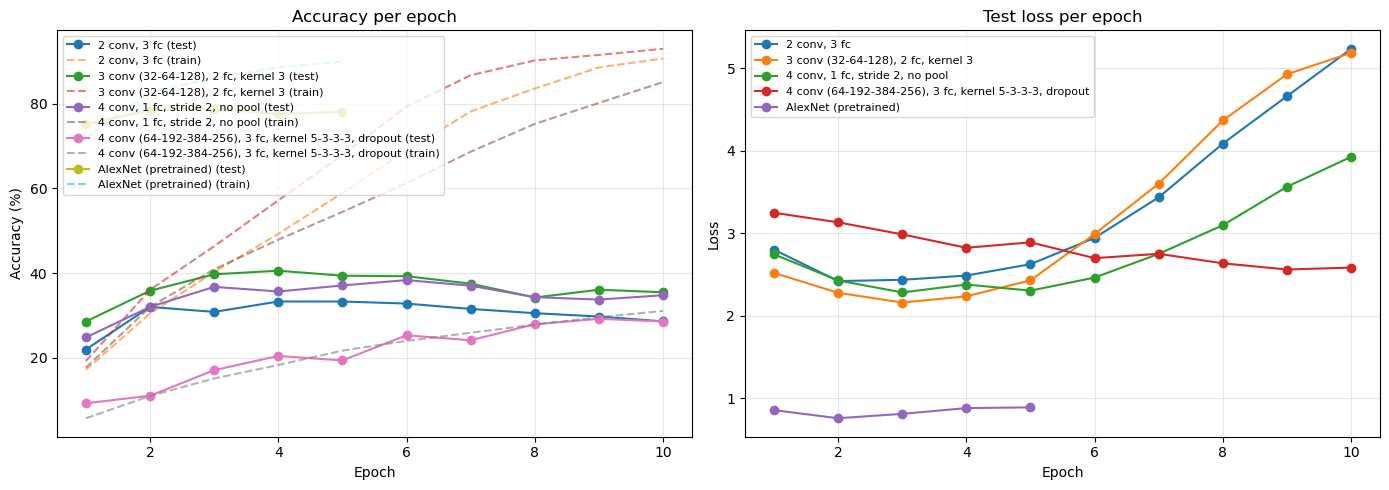

In [130]:
summary = pd.DataFrame({
    name: {'Final train acc (%)': h['train_acc'][-1],
           'Final test acc (%)':  h['test_acc'][-1],
           'Best test acc (%)':   max(h['test_acc']),
           'Time (min)':          h['time_min']}
    for name, h in results.items()
}).T.round(2)
display(summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, h in results.items():
    epochs = range(1, len(h['test_acc']) + 1)
    axes[0].plot(epochs, h['test_acc'], 'o-', label=f'{name} (test)')
    axes[0].plot(epochs, h['train_acc'], '--', alpha=0.6, label=f'{name} (train)')
    axes[1].plot(epochs, h['test_loss'], 'o-', label=name)
axes[0].set_title('Accuracy per epoch'); axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Accuracy (%)')
axes[1].set_title('Test loss per epoch'); axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Loss')
for ax in axes:
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 8. Save the best model

In [135]:
best_name = '3 conv (32-64-128), 2 fc, kernel 3'
trained_models[best_name]

ConvolutionalNeuralNetwork(
  (convs): ModuleList(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1))
    (1): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
    (2): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1))
  )
  (conv_drop): Dropout2d(p=0.0, inplace=False)
  (fc_drop): Dropout(p=0.0, inplace=False)
  (fcs): ModuleList(
    (0): Linear(in_features=8192, out_features=256, bias=True)
  )
  (out): Linear(in_features=256, out_features=33, bias=True)
)

In [136]:
best_name = '3 conv (32-64-128), 2 fc, kernel 3'

torch.save({
    'state_dict':  trained_models[best_name].state_dict(),
    'config':      configs[best_name],     # conv_channels, fc_units, ...
    'class_names': class_names,
    'history':     results[best_name],
}, 'model2_3conv_2fc.pt')

print('Saved model2_3conv_2fc.pt')

Saved model2_3conv_2fc.pt


### Part B – Step 1: Load the best model from Part A and the test data

Part B uses the model with the highest test accuracy from Part A: **Model 2** (3 conv layers with 32 → 64 → 128 filters, 3×3 kernels, max pooling, and 2 fc layers 256 → 33). It was saved as `model2_3conv_2fc.pt`.

This cell:

1. **Loads the test set** from `AI_ML_Assignment_4_Dataset/test` (3,300 images, 33 classes) using `ImageFolder`. `class_names` holds the class names in label order.
2. **Applies the same preprocessing as in Part A:** the images stay at their original **84×84** size (no resizing) and are normalised with the ImageNet mean and standard deviation. The model must see test images exactly the way it saw training images, otherwise its predictions and confidence values would not be meaningful.
3. **Loads the saved checkpoint**, which contains:
   * `config`: the architecture settings (conv channels, fc units), used to rebuild the same `ConvolutionalNeuralNetwork`;
   * `state_dict`: the trained weights, loaded into the rebuilt model.

In [ ]:
root = 'AI_ML_Assignment_4_Dataset'

# Same transform Part A used for the custom CNNs (no resize)
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])
test_data = datasets.ImageFolder(os.path.join(root, 'test'), transform=test_transform)
class_names = test_data.classes

checkpoint = torch.load('model2_3conv_2fc.pt', map_location='cpu', weights_only=False)
model = ConvolutionalNeuralNetwork(**checkpoint['config'])
model.load_state_dict(checkpoint['state_dict'])
model.eval()
print(checkpoint['config'])

{'conv_channels': [32, 64, 128], 'fc_units': [256], 'kernel_size': 3}


### Step 2: Confirm the loaded model's test accuracy

Before running the occlusion experiment, we check that the loaded model behaves the way it did at the end of Part A.

This cell:

1. **Creates a test `DataLoader`** with a batch size of 256 and `shuffle=False`. Since we only evaluate, the order doesn't matter, and larger batches make evaluation faster.
2. **Runs every test image through the model** inside `torch.no_grad()`. Gradients are not needed for evaluation, so turning them off saves memory and time.
3. **Takes the predicted class** for each image with `argmax(1)`, the class with the highest score, and counts how many predictions match the true labels.
4. **Prints the overall test accuracy** (correct predictions ÷ 3,300 test images).


In [5]:
# Confirm the loaded model's test accuracy
test_loader = DataLoader(test_data, batch_size=256, shuffle=False)
correct = 0
with torch.no_grad():
    for X, y in test_loader:
        correct += (model(X).argmax(1) == y).sum().item()
print(f'Test accuracy: {100 * correct / len(test_data):.2f}%')

Test accuracy: 35.45%


### Step 3: Select ~10 test images for the occlusion experiment

**1. Predict every test image once**
* Every test image is passed through the model (inside `torch.no_grad()`, as no training is involved).
* The model outputs `log_softmax` values, so `.exp()` turns them back into **probabilities** (each image's 33 values add up to 1).
* For each image we keep:
  * `preds`: the predicted class (the one with the highest probability);
  * `true_conf`: the probability the model gives to the **true** class, p(true). This is the same quantity the occlusion experiment will measure.

**2. Choose the images**
* Test images are sorted by p(true), from most confident to least confident.
* We walk down this list and keep an image only if:
  * it is **correctly classified** (prediction = true label), and
  * its class has **not been selected yet** (at most one image per class).
* We stop once **10 images** have been chosen.

**Why these criteria?**
* **Correctly classified, high confidence:** the occlusion experiment measures how much the true-class probability *drops* when part of the image is hidden. That only makes sense if the model recognises the image in the first place; a high starting confidence leaves room for a clear, visible drop.
* **One image per class:** gives 10 different classes, so we can compare how the model behaves on different kinds of images (e.g. animals vs. objects vs. textures like coral reef or spider web).

**3. Print the selection**
For each selected image, the cell prints its index in the test set, its class, and the model's confidence p(true) on the unoccluded image. That confidence is the baseline the occlusion results are compared against.


In [6]:
# Predict every test image once
all_probs, all_labels = [], []
with torch.no_grad():
    for X, y in test_loader:
        all_probs.append(model(X).exp())    # model returns log_softmax -> exp gives probabilities
        all_labels.append(y)
all_probs, all_labels = torch.cat(all_probs), torch.cat(all_labels)
preds = all_probs.argmax(1)
true_conf = all_probs[torch.arange(len(all_labels)), all_labels]

# Correctly classified, most confident first, at most one per class
order = true_conf.argsort(descending=True)
selected, used_classes = [], set()
for idx in order.tolist():
    lbl = all_labels[idx].item()
    if preds[idx] == lbl and lbl not in used_classes:
        selected.append(idx)
        used_classes.add(lbl)
    if len(selected) == 10:
        break

for idx in selected:
    print(f'{idx:5}  {class_names[all_labels[idx]]:22} p(true) = {true_conf[idx]:.3f}')


  955  consomme               p(true) = 1.000
 2471  photocopier            p(true) = 1.000
 1365  fire_screen            p(true) = 1.000
 1733  ladybug                p(true) = 1.000
 1902  lipstick               p(true) = 1.000
  653  catamaran              p(true) = 1.000
 1808  lion                   p(true) = 1.000
 2101  orange                 p(true) = 1.000
 2519  rhinoceros_beetle      p(true) = 1.000
 2690  slot                   p(true) = 1.000


### Step 4: The occlusion sensitivity function

`occlusion_map(model, image, label, N, stride, gray, batch_size)` carries out the experiment described in the assignment, following Zeiler & Fergus (Figures 7–8). For each pixel position (i, j), it hides an **N×N square** of the image centred at (i, j) and records how confident the model still is about the **true class**. The result is a map, `confidence[i, j]`, with one value per position.

#### Inputs

| Argument | Meaning |
|---|---|
| `model` | the trained Model 2, in evaluation mode |
| `image` | one normalised test image, shape (3, 84, 84) |
| `label` | the image's true class index |
| `N` | size of the gray occluding square (default 15 × 15 pixels) |
| `stride` | how far the square moves between positions (1 = every pixel, as the assignment asks) |
| `gray` | value used to fill the square. **0.0 in normalised space equals the mean pixel colour (a neutral gray)**, so it removes information without adding a strong colour of its own |
| `batch_size` | how many occluded images are sent through the model at once (512) |

#### How it works

1. **List every position to occlude.**
   `positions` holds every (row i, column j) pair in the image, stepping by `stride`. With stride 1 that is 84 × 84 = **7,056 positions**, so 7,056 occluded versions of the image. `conf` is an empty 84×84 map that will hold the results.

2. **Process the positions in batches.**
   Running 7,056 images through the model one at a time would be slow. The positions are therefore split into chunks of 512. For each chunk, the original image is copied once per position (`image.unsqueeze(0).repeat(...)`), giving a batch of identical images.

3. **Place the gray square on each copy.**
   For copy *k* with position (i, j), the pixels from rows `i − N//2` to `i + N//2` and columns `j − N//2` to `j + N//2` are set to `gray`, so the square is **centred at (i, j)**.
   * `max(0, …)` clips the square at the top and left edges. Python slicing clips the bottom and right edges automatically. Near the border, only the part of the square that fits inside the image is grayed out.

4. **Ask the model how confident it is.**
   The batch of occluded images goes through the model in one call, inside `torch.no_grad()` since nothing is being trained. The model outputs `log_softmax`, so `.exp()` turns it back into probabilities, and `[:, label]` keeps only the **probability of the true class** for each occluded copy.

5. **Store each result in the map.**
   Each probability is written to `conf[i, j]`, at the position that was occluded. (Dividing by `stride` only matters if stride > 1, in which case the map is smaller than the image.)

6. **Return the confidence map:** an 84×84 tensor, ready to be plotted as an image.

#### How to read the map

* **Low values (dark blue):** hiding this region makes the model much less sure of the true class, so **the model relies on this region**.
* **High values (red):** hiding this region barely matters, or even increases confidence, so this region is **not important** (or was pointing the model towards another class).
* If the low-confidence areas sit **on the object**, the model has learnt the object itself. If they sit **on the background** (water, grass, shelves), the model is using **contextual cues**.

#### Choice of N

The images are 84×84, so N = 15 covers about 18% of the image width. That's big enough to hide a meaningful part of the object (an eye, a beak, a wheel), but small enough that the map still shows *where* in the image the important regions are. A very small N barely changes the image. A very large N hides most of it and blurs the map.


In [7]:
def occlusion_map(model, image, label, N=15, stride=1, gray=0.0, batch_size=512):
    """
    image: normalised tensor (3, H, W). Returns confidence[i, j] = p(true class)
    with an N x N gray window centred at (row i, column j).
    """
    _, H, W = image.shape
    half = N // 2
    positions = [(i, j) for i in range(0, H, stride) for j in range(0, W, stride)]
    conf = torch.zeros(len(range(0, H, stride)), len(range(0, W, stride)))

    with torch.no_grad():
        for start in range(0, len(positions), batch_size):
            chunk = positions[start:start + batch_size]
            batch = image.unsqueeze(0).repeat(len(chunk), 1, 1, 1)
            for k, (i, j) in enumerate(chunk):
                # window centred at (i, j), clipped at the image border
                batch[k, :, max(0, i - half):i + half + 1, max(0, j - half):j + half + 1] = gray
            probs = model(batch).exp()[:, label]
            for k, (i, j) in enumerate(chunk):
                conf[i // stride, j // stride] = probs[k]
    return conf


### Step 5: Run the occlusion experiment and plot the results

This cell runs `occlusion_map` on each of the 10 selected test images and shows the results as a grid: **one row per image, three panels per row**.

#### What the code does

1. **Prepares images for display.**
   The test images are normalised (ImageNet mean/std), so shown directly they would look washed out or strangely coloured. `to_display()` reverses the normalisation (`img × std + mean`), clips values to the valid 0–1 range, and reorders the dimensions from (channels, height, width) to (height, width, channels), the layout matplotlib expects.

2. **Sets the window size**: `N = 15`, a 15×15 gray square on an 84×84 image.

3. **For each selected image:**
   * loads the image and its true label from the test set;
   * calls `occlusion_map(...)` to compute the 84×84 confidence map. That is 7,056 occluded versions of the image, each passed through the model;
   * saves the map in `occlusion_results`, so it can be reused later without recomputing;
   * looks up `base`, the model's confidence in the true class on the **unoccluded** image (from Step 3).

4. **Draws three panels:**

| Panel | Shows |
|---|---|
| **1. Original image** | the test image, with its true class and baseline confidence p(true) |
| **2. Confidence map** | `confidence(i, j)` as a heatmap: each pixel's colour is the model's p(true) **when the gray square is centred at that pixel**. The colour scale is fixed from 0 (dark blue) to 1 (dark red) for every image, so maps can be compared. The title shows the lowest and highest confidence reached |
| **3. Overlay** | the heatmap drawn semi-transparently (`alpha=0.5`) over the original image, so the important regions can be matched to parts of the image |

#### How to read the results

**Start from the baseline.** The p(true) above the original image is the model's confidence with nothing hidden. Every value in the map should be compared to it:

* **Much lower than the baseline (blue regions):** hiding this area makes the model lose confidence in the true class, so **this region is important for the model's decision**.
* **About the same as the baseline:** hiding this area makes no difference, so **the model doesn't use this region**.
* **Higher than the baseline:** hiding this area makes the model *more* sure of the true class. This region was **misleading** the model, pulling it towards another class.

**Then match the blue regions to the image (overlay panel):**

* **Blue on the object** (the animal's head, the vase's shape, the ladybug's shell): the model has learnt to recognise **the object itself**, which is the desired behaviour.
* **Blue on the background** (water around a catamaran, shelves behind a bookshop, grass around a lion): the model relies on **contextual cues**. It recognises the scene the object usually appears in, rather than the object.
* **Blue spread over the whole image:** typical for **texture-like classes** (coral reef, spider web, consommé), where the "object" fills the image and no single region is decisive.
* **Little colour change anywhere:** no single 15×15 region is critical. The model uses information spread across the image, or N is too small to hide a meaningful part.

**The min/max values in the title** summarise the effect. A large gap (e.g. min 0.05 / max 0.95) means one region strongly drives the decision. A small gap means occlusion barely matters.

#### Note on the colour scale

The scale is fixed at 0–1, so an image with a modest baseline (e.g. p(true) = 0.40) can never look dark red, and its map will look mostly cool-coloured. Judge each map against **its own baseline**, not against the colours of the other rows.


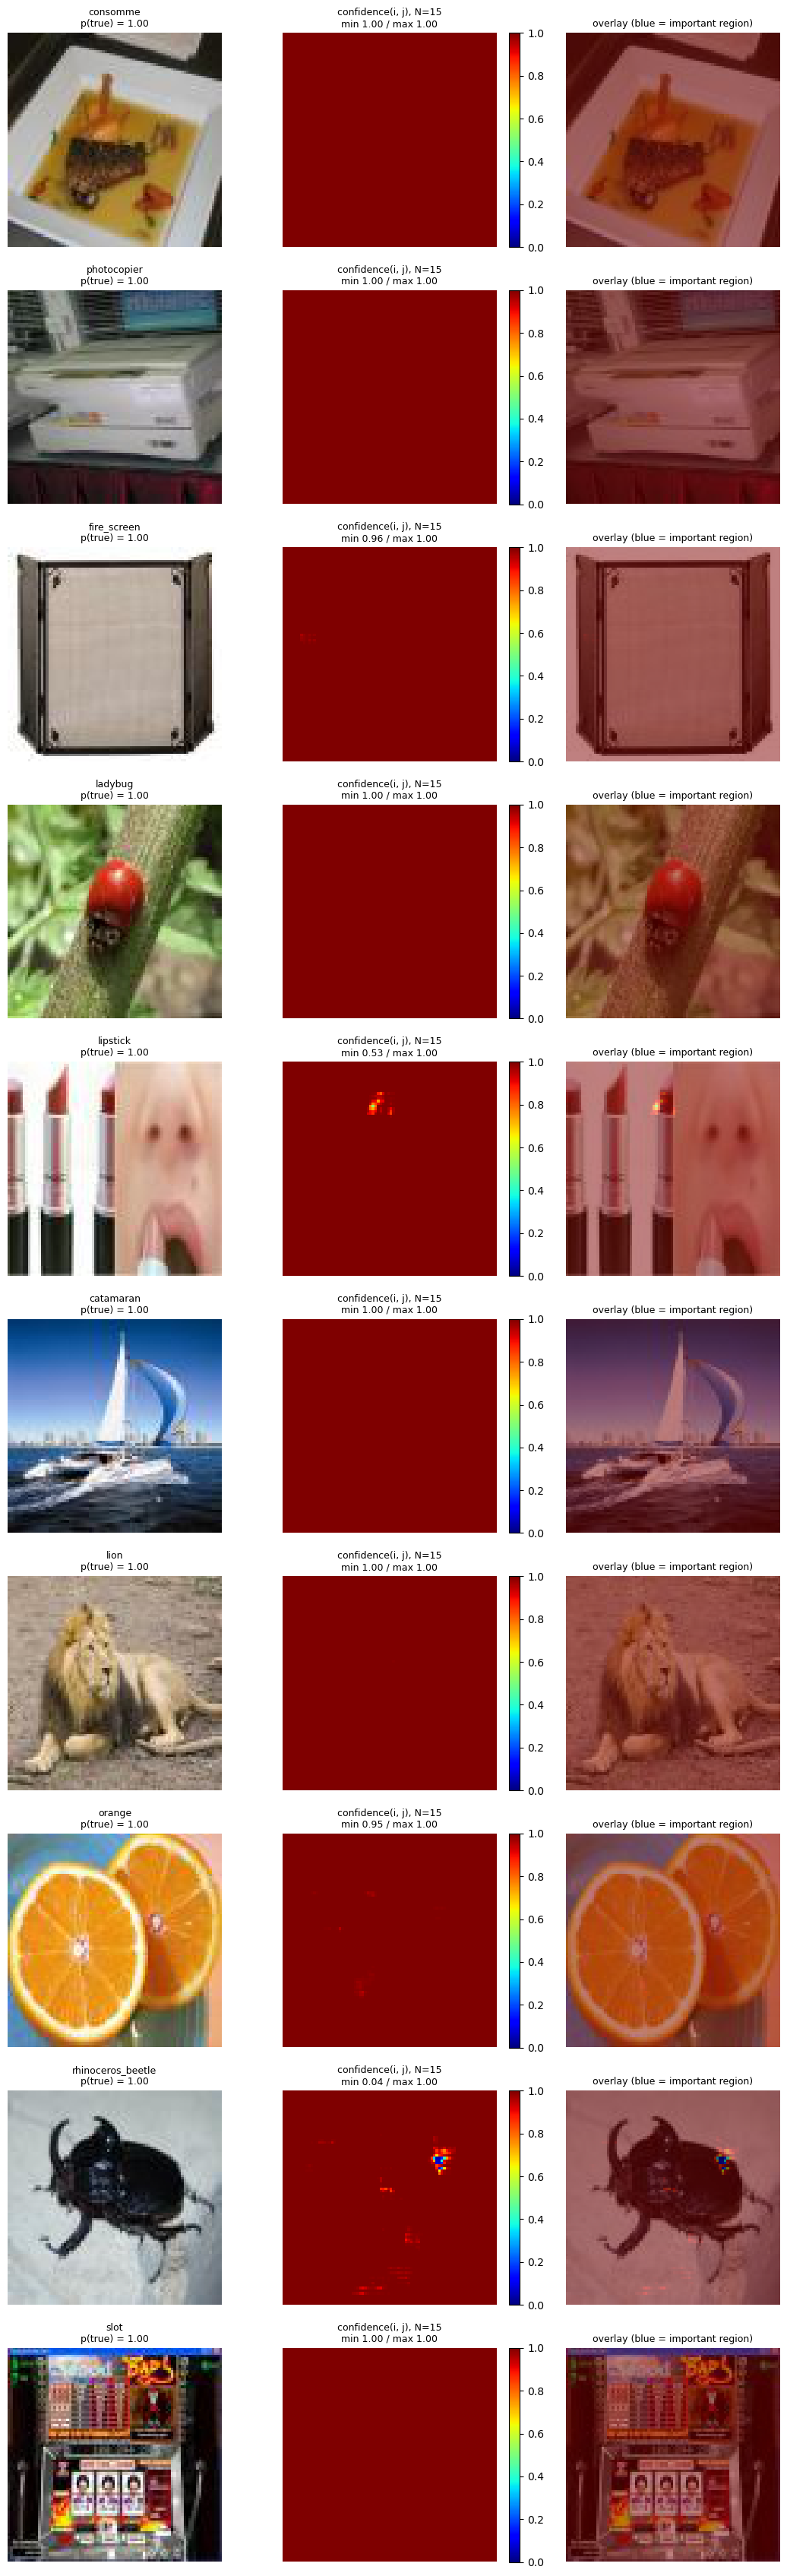

In [8]:
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
def to_display(img):   # undo normalisation for plotting
    return (img * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

N = 15
occlusion_results = {}

fig, axes = plt.subplots(len(selected), 3, figsize=(11, 3.4 * len(selected)))
for row, idx in enumerate(selected):
    image, label = test_data[idx]
    conf = occlusion_map(model, image, label, N=N)
    occlusion_results[idx] = conf
    base = true_conf[idx].item()

    axes[row, 0].imshow(to_display(image))
    axes[row, 0].set_title(f'{class_names[label]}\np(true) = {base:.2f}', fontsize=9)

    im = axes[row, 1].imshow(conf, cmap='jet', vmin=0, vmax=1)
    axes[row, 1].set_title(f'confidence(i, j), N={N}\nmin {conf.min():.2f} / max {conf.max():.2f}', fontsize=9)
    fig.colorbar(im, ax=axes[row, 1], fraction=0.046)

    axes[row, 2].imshow(to_display(image))
    axes[row, 2].imshow(conf, cmap='jet', vmin=0, vmax=1, alpha=0.5)
    axes[row, 2].set_title('overlay (blue = important region)', fontsize=9)

    for ax in axes[row]:
        ax.axis('off')
plt.tight_layout()
plt.show()
